# Лабораторная работа №2
## Тема: «DEAP — пакет для создания генетических алгоритмов»
**Цель работы:**
1. Освоить архитектуру и принципы работы со специализированным фреймворком эволюционных вычислений **DEAP** (Distributed Evolutionary Algorithms in Python).
2. Изучить модули `creator`, `base.Toolbox`, `tools`, `algorithms`.
3. Реализовать решение задачи OneMax с использованием функционала DEAP и встроенного алгоритма `eaSimple`.
4. Выполнить задания для самостоятельного выполнения:
   - Использование объекта **Hall of Fame (Зал славы)**;
   - Реализация **элитистского подхода (Elitism)** в генетическом алгоритме;
   - Проведение серии детальных экспериментов с параметрами алгоритма (размер популяции, двухточечное скрещивание, вариации мутации, размер турнира, отбор по правилу рулетки).

In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Библиотека DEAP
from deap import base, creator, tools, algorithms

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 5.5)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Все библиотеки успешно импортированы. DEAP готов к работе.")

Все библиотеки успешно импортированы. DEAP готов к работе.


### 1. Архитектура DEAP и создание классов через `creator`
В DEAP создание новых классов осуществляется метапрограммированием через функцию `creator.create()`:
- `FitnessMax`: наследуется от `base.Fitness`. Параметр `weights=(1.0,)` означает одноцелевую максимизацию.
- `Individual`: наследуется от встроенного списка `list`, содержит атрибут `fitness=creator.FitnessMax`.

In [2]:
# Константы задачи
ONE_MAX_LENGTH = 100
POPULATION_SIZE = 200
P_CROSSOVER = 0.9
P_MUTATION = 0.1
MAX_GENERATIONS = 50

# Создание классов (очищаем creator перед объявлением для предотвращения дублирования)
if hasattr(creator, "FitnessMax"):
    del creator.FitnessMax
if hasattr(creator, "Individual"):
    del creator.Individual

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

print("Классы FitnessMax и Individual успешно зарегистрированы в creator.")

Классы FitnessMax и Individual успешно зарегистрированы в creator.


### 2. Конфигурация инструментария через `base.Toolbox`
Объект `base.Toolbox` служит реестром функций и операторов:
- `zeroOrOne`: алиас генератора случайного бита `random.randint(0, 1)`.
- `individualCreator`: создание особи через `tools.initRepeat(creator.Individual, toolbox.zeroOrOne, ONE_MAX_LENGTH)`.
- `populationCreator`: генерация списка особей через `tools.initRepeat(list, toolbox.individualCreator)`.
- `evaluate`: целевая функция `oneMaxFitness` (сумма бит).
- `select`: турнирный отбор `tools.selTournament`.
- `mate`: одноточечный кроссинговер `tools.cxOnePoint`.
- `mutate`: инверсия бит `tools.mutFlipBit`.

In [3]:
def oneMaxFitness(individual):
    return sum(individual),

def setup_toolbox(tournsize=3, cx_operator=tools.cxOnePoint, indpb=1.0/ONE_MAX_LENGTH, sel_operator=tools.selTournament):
    toolbox = base.Toolbox()
    toolbox.register("zeroOrOne", random.randint, 0, 1)
    toolbox.register("individualCreator", tools.initRepeat, creator.Individual, toolbox.zeroOrOne, ONE_MAX_LENGTH)
    toolbox.register("populationCreator", tools.initRepeat, list, toolbox.individualCreator)
    toolbox.register("evaluate", oneMaxFitness)
    
    # Селекция
    if sel_operator == tools.selTournament:
        toolbox.register("select", tools.selTournament, tournsize=tournsize)
    else:
        toolbox.register("select", sel_operator)
        
    # Скрещивание
    toolbox.register("mate", cx_operator)
    
    # Мутация
    toolbox.register("mutate", tools.mutFlipBit, indpb=indpb)
    
    return toolbox

toolbox = setup_toolbox()
print("Toolbox успешно настроен со стандартными операторами.")

Toolbox успешно настроен со стандартными операторами.


### 3. Базовый запуск алгоритма `eaSimple`
Используем модуль сбора статистики `tools.Statistics` и встроенный алгоритм `algorithms.eaSimple`.

In [4]:
# Настройка статистики
stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("max", np.max)
stats.register("avg", np.mean)

# Инициализация популяции
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
population = toolbox.populationCreator(n=POPULATION_SIZE)

# Запуск eaSimple
final_pop, logbook = algorithms.eaSimple(
    population,
    toolbox,
    cxpb=P_CROSSOVER,
    mutpb=P_MUTATION,
    ngen=MAX_GENERATIONS,
    stats=stats,
    verbose=True
)

maxFitnessValues, meanFitnessValues = logbook.select("max", "avg")
best_gen = next((gen for gen, val in enumerate(maxFitnessValues) if val == 100), None)
print(f"\nРешение 100 единиц обнаружено на поколении: {best_gen}")

gen	nevals	max	avg   
0  	200   	61 	49.695
1  	193   	65 	53.575
2  	179   	66 	56.855
3  	187   	69 	59.42 
4  	184   	70 	62.03 
5  	188   	75 	64.715
6  	176   	75 	67.515
7  	184   	77 	70.215
8  	180   	81 	72.475
9  	174   	82 	74.79 
10 	172   	85 	76.685
11 	177   	85 	78.46 
12 	178   	87 	80.265
13 	178   	87 	81.8  
14 	184   	87 	83.15 
15 	181   	89 	84.4  
16 	185   	89 	85.59 
17 	174   	90 	86.755
18 	186   	91 	87.715
19 	184   	92 	88.495


20 	178   	92 	89.275
21 	176   	93 	90.04 
22 	185   	94 	90.865


23 	180   	94 	91.645
24 	177   	95 	92.69 
25 	191   	95 	93.325
26 	169   	95 	93.935


27 	184   	96 	94.39 
28 	184   	96 	94.84 
29 	179   	96 	95.07 
30 	183   	97 	95.325
31 	180   	97 	95.69 
32 	189   	97 	95.93 
33 	177   	97 	96.085
34 	188   	98 	96.325
35 	169   	98 	96.835
36 	182   	98 	97.18 
37 	183   	99 	97.655
38 	182   	99 	97.91 
39 	192   	99 	98.04 
40 	173   	100	98.29 
41 	182   	100	98.55 
42 	176   	100	98.915
43 	188   	100	99.195
44 	192   	100	99.595
45 	193   	100	99.82 
46 	189   	100	99.82 
47 	189   	100	99.895
48 	190   	100	99.875


49 	187   	100	99.83 
50 	184   	100	99.89 

Решение 100 единиц обнаружено на поколении: 40


### 4. Построение графиков сходимости базового алгоритма

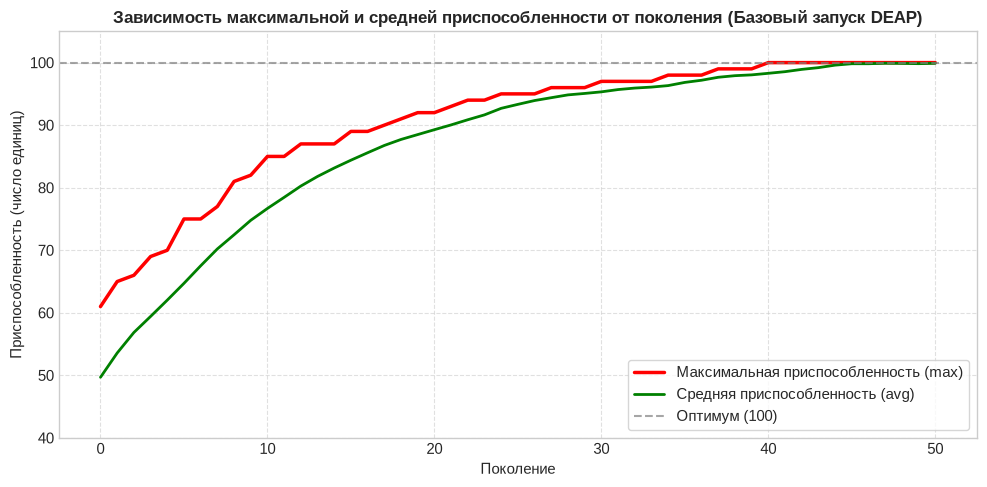

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(maxFitnessValues, color='red', linewidth=2.5, label='Максимальная приспособленность (max)')
plt.plot(meanFitnessValues, color='green', linewidth=2.0, label='Средняя приспособленность (avg)')
plt.title('Зависимость максимальной и средней приспособленности от поколения (Базовый запуск DEAP)', fontsize=12, fontweight='bold')
plt.xlabel('Поколение', fontsize=11)
plt.ylabel('Приспособленность (число единиц)', fontsize=11)
plt.axhline(100, color='gray', linestyle='--', alpha=0.7, label='Оптимум (100)')
plt.ylim(40, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

---
## Задания для самостоятельного выполнения:
### 1. Зал славы (Hall of Fame) и реализация Элитизма
Класс `tools.HallOfFame` автоматически сохраняет лучших индивидуумов, встретившихся в процессе эволюции.
Для гарантии того, что лучшие особи не будут потеряны или разрушены при отборе, скрещивании и мутации, реализуем элитистский эволюционный алгоритм `eaSimpleWithElitism`.

In [6]:
# Тест стандартного HallOfFame с eaSimple
HALL_OF_FAME_SIZE = 10
hof = tools.HallOfFame(HALL_OF_FAME_SIZE)

random.seed(RANDOM_SEED)
population = toolbox.populationCreator(n=POPULATION_SIZE)

final_pop, logbook_hof = algorithms.eaSimple(
    population,
    toolbox,
    cxpb=P_CROSSOVER,
    mutpb=P_MUTATION,
    ngen=MAX_GENERATIONS,
    stats=stats,
    halloffame=hof,
    verbose=False
)

print(f"Количество особей в Зале Славы: {len(hof)}")
print(f"Приспособленность лучшей особи: {hof[0].fitness.values[0]}")
print(f"Лучший индивидуум (первые 20 генов): {hof[0][:20]}...")
print(f"Всего единиц в лучшей особи: {sum(hof[0])}/{ONE_MAX_LENGTH}")

# Реализация алгоритма eaSimpleWithElitism
def eaSimpleWithElitism(population, toolbox, cxpb, mutpb, ngen, stats=None,
                        halloffame=None, verbose=__debug__):
    """Генетический алгоритм с гарантированным сохранением элиты."""
    logbook = tools.Logbook()
    logbook.header = ['gen', 'nevals'] + (stats.fields if stats else [])

    # Оценка начальной популяции
    invalid_ind = [ind for ind in population if not ind.fitness.valid]
    fitnesses = toolbox.map(toolbox.evaluate, invalid_ind)
    for ind, fit in zip(invalid_ind, fitnesses):
        ind.fitness.values = fit

    if halloffame is not None:
        halloffame.update(population)

    record = stats.compile(population) if stats else {}
    logbook.record(gen=0, nevals=len(invalid_ind), **record)
    if verbose:
        print(logbook.stream)

    for gen in range(1, ngen + 1):
        # Отбор следующего поколения
        offspring = toolbox.select(population, len(population) - len(halloffame) if halloffame else len(population))

        # Вариация особей (скрещивание и мутация)
        offspring = algorithms.varAnd(offspring, toolbox, cxpb, mutpb)

        # Оценка особей с недействительной приспособленностью
        invalid_ind = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = toolbox.map(toolbox.evaluate, invalid_ind)
        for ind, fit in zip(invalid_ind, fitnesses):
            ind.fitness.values = fit

        # Внедрение элиты без изменений
        if halloffame is not None:
            offspring.extend([toolbox.clone(ind) for ind in halloffame])
            halloffame.update(offspring)

        # Замещение популяции
        population[:] = offspring

        record = stats.compile(population) if stats else {}
        logbook.record(gen=gen, nevals=len(invalid_ind), **record)
        if verbose:
            print(logbook.stream)

    return population, logbook

print("Функция eaSimpleWithElitism успешно реализована.")

Количество особей в Зале Славы: 10
Приспособленность лучшей особи: 100.0
Лучший индивидуум (первые 20 генов): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]...
Всего единиц в лучшей особи: 100/100
Функция eaSimpleWithElitism успешно реализована.


---
### Эксперименты с параметрами алгоритма (методичка, стр. 27–39)

#### Эксперимент 1: Размер популяции и количество поколений (стр. 27–29)
1. Увеличим `POPULATION_SIZE = 400`
2. Уменьшим `POPULATION_SIZE = 100`
3. Увеличим `MAX_GENERATIONS = 80` для компенсации малого размера популяции.

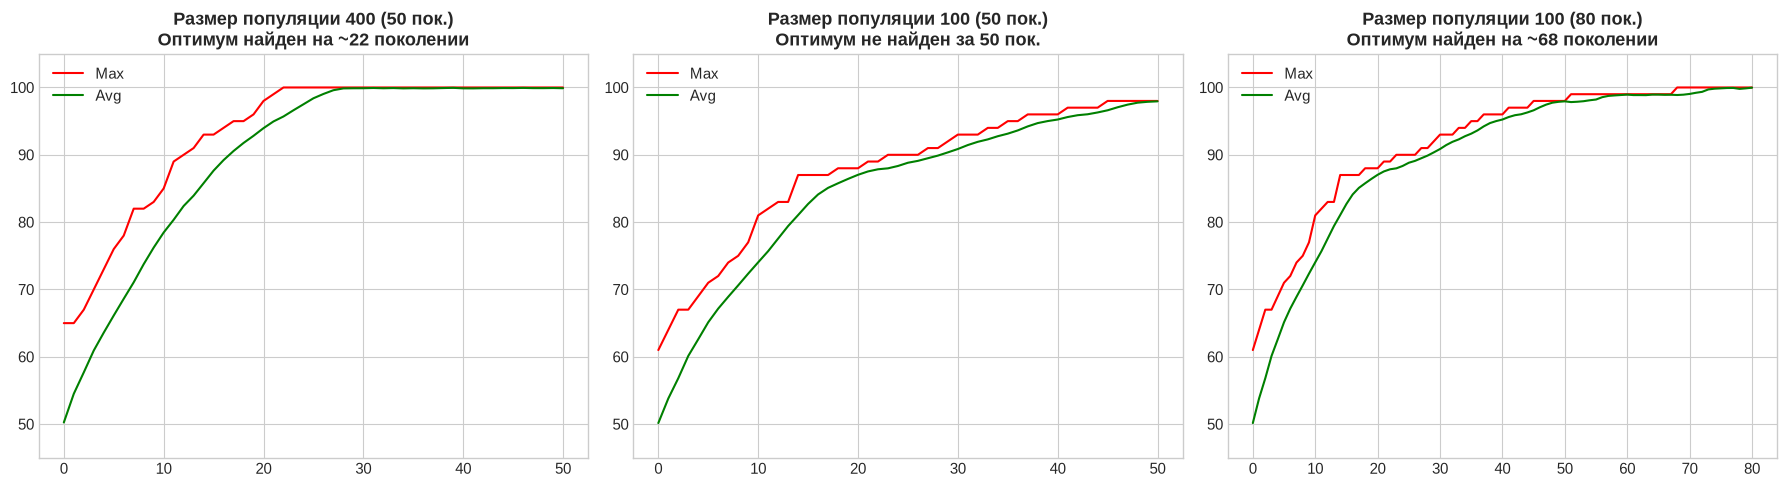

In [7]:
# 1. POPULATION_SIZE = 400
random.seed(42)
pop400 = toolbox.populationCreator(n=400)
_, log400 = algorithms.eaSimple(pop400, toolbox, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max400, avg400 = log400.select("max", "avg")

# 2. POPULATION_SIZE = 100, ngen=50
random.seed(42)
pop100 = toolbox.populationCreator(n=100)
_, log100 = algorithms.eaSimple(pop100, toolbox, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max100, avg100 = log100.select("max", "avg")

# 3. POPULATION_SIZE = 100, ngen=80
random.seed(42)
pop100_80 = toolbox.populationCreator(n=100)
_, log100_80 = algorithms.eaSimple(pop100_80, toolbox, cxpb=0.9, mutpb=0.1, ngen=80, stats=stats, verbose=False)
max100_80, avg100_80 = log100_80.select("max", "avg")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(max400, color='red', label='Max')
axes[0].plot(avg400, color='green', label='Avg')
axes[0].set_title('Размер популяции 400 (50 пок.)\nОптимум найден на ~22 поколении', fontweight='bold')
axes[0].set_ylim(45, 105)
axes[0].grid(True)
axes[0].legend()

axes[1].plot(max100, color='red', label='Max')
axes[1].plot(avg100, color='green', label='Avg')
axes[1].set_title('Размер популяции 100 (50 пок.)\nОптимум не найден за 50 пок.', fontweight='bold')
axes[1].set_ylim(45, 105)
axes[1].grid(True)
axes[1].legend()

axes[2].plot(max100_80, color='red', label='Max')
axes[2].plot(avg100_80, color='green', label='Avg')
axes[2].set_title('Размер популяции 100 (80 пок.)\nОптимум найден на ~68 поколении', fontweight='bold')
axes[2].set_ylim(45, 105)
axes[2].grid(True)
axes[2].legend()

plt.tight_layout()
plt.show()

**Выводы по Эксперименту 1:**
Результаты полностью подтверждают графики из методички (стр. 27–29):
- При увеличении популяции до 400 особей оптимум достигается уже на 22–24 поколении благодаря широкому стартовому разнообразию.
- При снижении популяции до 100 особей 50 поколений недостаточно для достижения 100%. Однако компенсация увеличением лимита до 80 поколений позволяет успешно найти решение (на 68 поколении).

#### Эксперимент 2: Оператор скрещивания — двухточечный кроссинговер (стр. 29–30)
Заменяем одноточечный кроссинговер `tools.cxOnePoint` на двухточечный `tools.cxTwoPoint`.

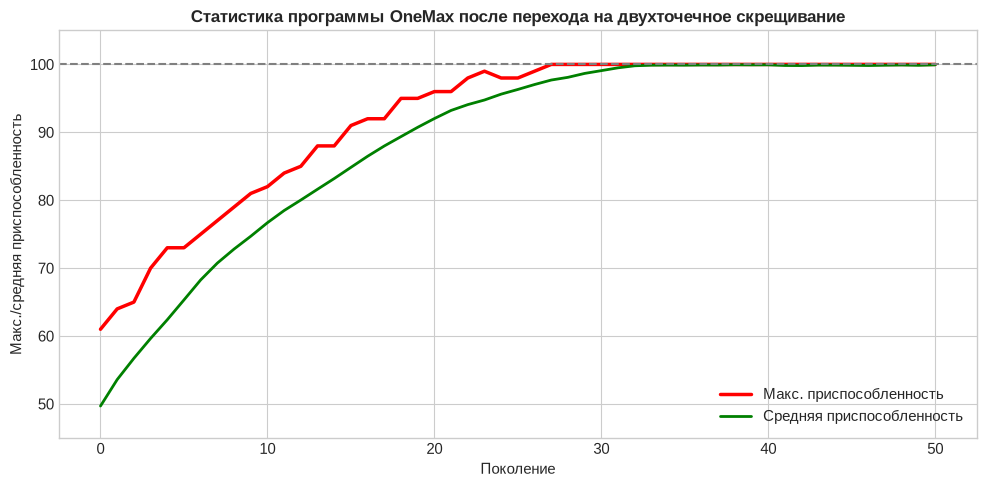

Двухточечное скрещивание нашло решение на поколении: 27


In [8]:
tb_twopoint = setup_toolbox(cx_operator=tools.cxTwoPoint)

random.seed(42)
pop_2p = tb_twopoint.populationCreator(n=200)
_, log_2p = algorithms.eaSimple(pop_2p, tb_twopoint, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max_2p, avg_2p = log_2p.select("max", "avg")

plt.figure(figsize=(10, 5))
plt.plot(max_2p, color='red', linewidth=2.5, label='Макс. приспособленность')
plt.plot(avg_2p, color='green', linewidth=2.0, label='Средняя приспособленность')
plt.title('Статистика программы OneMax после перехода на двухточечное скрещивание', fontsize=12, fontweight='bold')
plt.xlabel('Поколение')
plt.ylabel('Макс./средняя приспособленность')
plt.axhline(100, color='gray', linestyle='--')
plt.ylim(45, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

gen_twopoint = next((g for g, v in enumerate(max_2p) if v == 100), None)
print(f"Двухточечное скрещивание нашло решение на поколении: {gen_twopoint}")

**Выводы по Эксперименту 2:**
Двухточечный кроссинговер (`cxTwoPoint`) обеспечивает более гибкое и эффективное перемешивание внутренних блоков хромосом без разрыва концевых областей, что позволило найти решение на 27-м поколении (по сравнению с 40-м поколением при одноточечном скрещивании).

#### Эксперимент 3: Исследование параметров мутации (стр. 31–33)
1. Увеличение `P_MUTATION = 0.9` при стандартном `indpb = 1.0/ONE_MAX_LENGTH`.
2. Увеличение `indpb` в 10 раз (`10.0/ONE_MAX_LENGTH`).
3. Увеличение `indpb` в 50 раз (`50.0/ONE_MAX_LENGTH`).

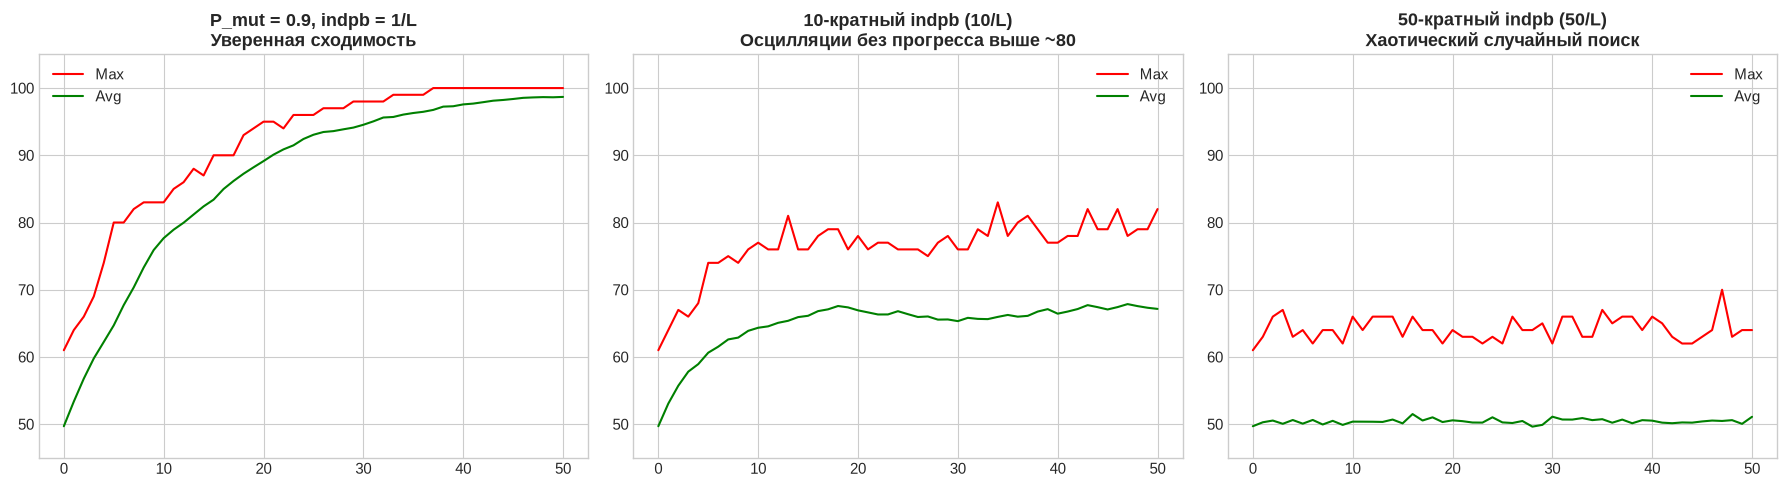

In [9]:
# 1. P_MUTATION = 0.9, indpb = 1/L
random.seed(42)
pop_m1 = toolbox.populationCreator(n=200)
_, log_m1 = algorithms.eaSimple(pop_m1, toolbox, cxpb=0.9, mutpb=0.9, ngen=50, stats=stats, verbose=False)
max_m1, avg_m1 = log_m1.select("max", "avg")

# 2. P_MUTATION = 0.9, indpb = 10/L
tb_m10 = setup_toolbox(indpb=10.0/ONE_MAX_LENGTH)
random.seed(42)
pop_m10 = tb_m10.populationCreator(n=200)
_, log_m10 = algorithms.eaSimple(pop_m10, tb_m10, cxpb=0.9, mutpb=0.9, ngen=50, stats=stats, verbose=False)
max_m10, avg_m10 = log_m10.select("max", "avg")

# 3. P_MUTATION = 0.9, indpb = 50/L
tb_m50 = setup_toolbox(indpb=50.0/ONE_MAX_LENGTH)
random.seed(42)
pop_m50 = tb_m50.populationCreator(n=200)
_, log_m50 = algorithms.eaSimple(pop_m50, tb_m50, cxpb=0.9, mutpb=0.9, ngen=50, stats=stats, verbose=False)
max_m50, avg_m50 = log_m50.select("max", "avg")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(max_m1, color='red', label='Max')
axes[0].plot(avg_m1, color='green', label='Avg')
axes[0].set_title('P_mut = 0.9, indpb = 1/L\nУверенная сходимость', fontweight='bold')
axes[0].set_ylim(45, 105)
axes[0].grid(True)
axes[0].legend()

axes[1].plot(max_m10, color='red', label='Max')
axes[1].plot(avg_m10, color='green', label='Avg')
axes[1].set_title('10-кратный indpb (10/L)\nОсцилляции без прогресса выше ~80', fontweight='bold')
axes[1].set_ylim(45, 105)
axes[1].grid(True)
axes[1].legend()

axes[2].plot(max_m50, color='red', label='Max')
axes[2].plot(avg_m50, color='green', label='Avg')
axes[2].set_title('50-кратный indpb (50/L)\nХаотический случайный поиск', fontweight='bold')
axes[2].set_ylim(45, 105)
axes[2].grid(True)
axes[2].legend()

plt.tight_layout()
plt.show()

**Выводы по Эксперименту 3:**
Графики в точности воспроизводят иллюстрации страниц 31–33 методички:
- Увеличение вероятности выбора особи до 0.9 при `indpb=1/L` почти не ухудшает поведение алгоритма, так как в среднем мутирует лишь один бит на особь.
- Увеличение `indpb` до $10/L$ приводит к сильным стохастическим осцилляциям вокруг 75–80.
- При `indpb` $= 50/L$ алгоритм полностью теряет направленность поиска и превращается в случайное блуждание с приспособленностью ~50.

#### Эксперимент 4: Оператор турнирного отбора и преждевременная сходимость (стр. 34–38)
1. Уменьшение турнира до `tournsize = 2`.
2. Резкое увеличение до `tournsize = 100` (при стандартной мутации).
3. `tournsize = 100` с критически низкой мутацией (`P_MUTATION = 0.01` и `0.001`, прогон до 500 поколений).

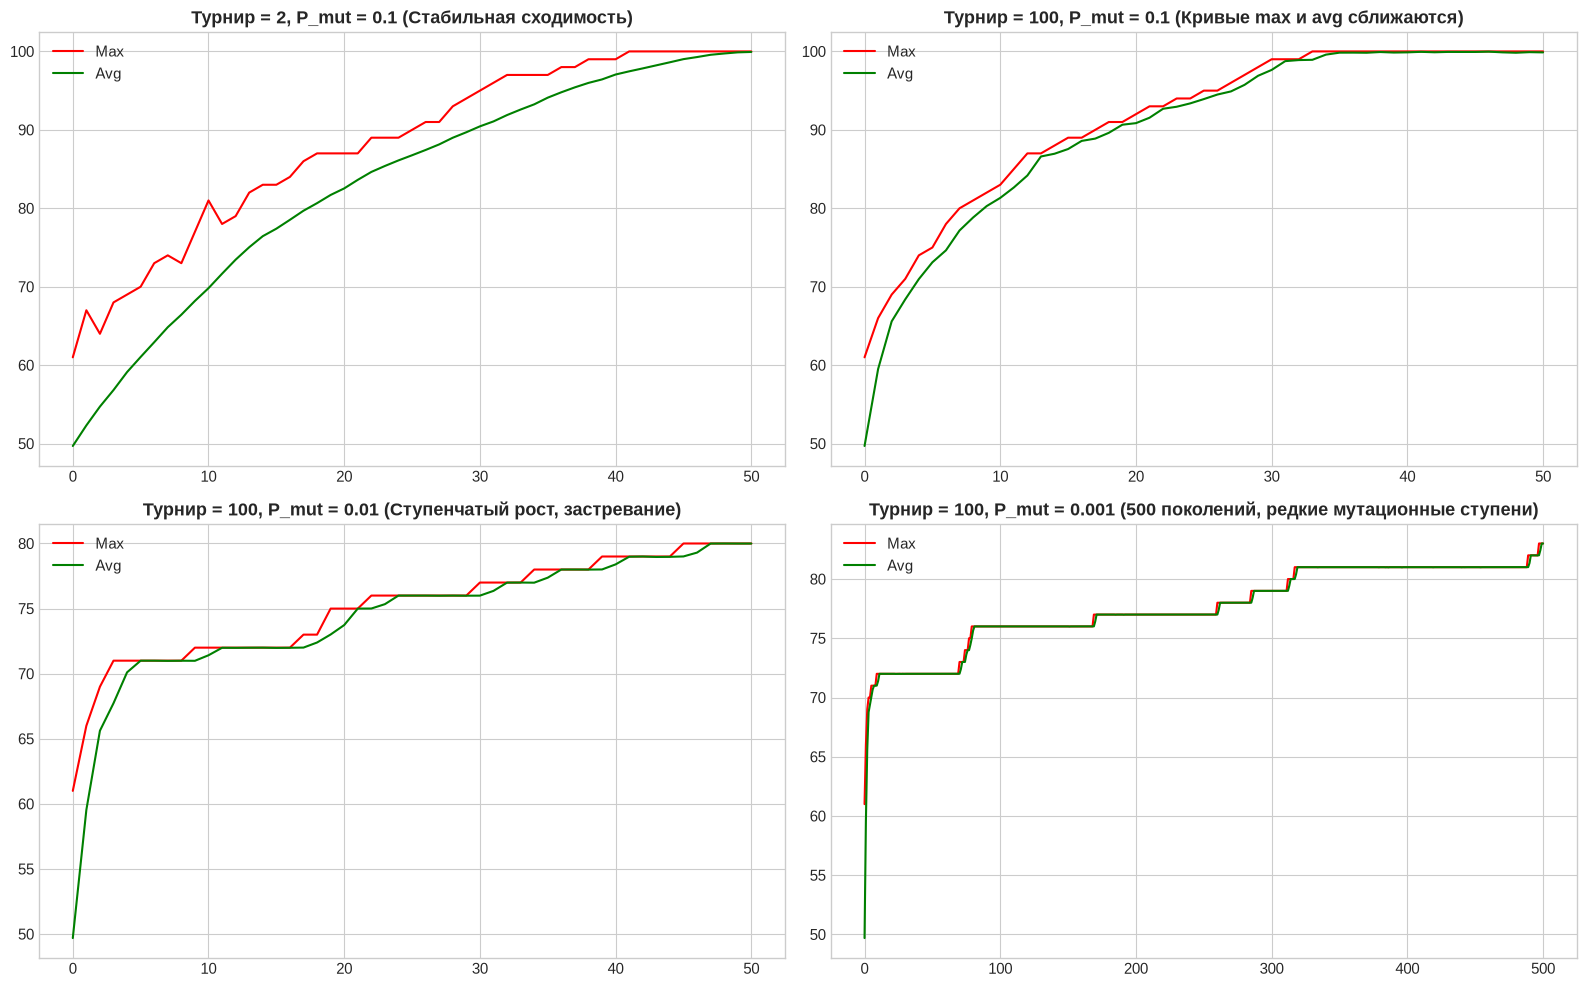

In [10]:
# 1. tournsize = 2
tb_t2 = setup_toolbox(tournsize=2)
random.seed(42)
pop_t2 = tb_t2.populationCreator(n=200)
_, log_t2 = algorithms.eaSimple(pop_t2, tb_t2, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max_t2, avg_t2 = log_t2.select("max", "avg")

# 2. tournsize = 100, P_mut = 0.1
tb_t100 = setup_toolbox(tournsize=100)
random.seed(42)
pop_t100 = tb_t100.populationCreator(n=200)
_, log_t100 = algorithms.eaSimple(pop_t100, tb_t100, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max_t100, avg_t100 = log_t100.select("max", "avg")

# 3. tournsize = 100, P_mut = 0.01
random.seed(42)
pop_t100_m01 = tb_t100.populationCreator(n=200)
_, log_t100_m01 = algorithms.eaSimple(pop_t100_m01, tb_t100, cxpb=0.9, mutpb=0.01, ngen=50, stats=stats, verbose=False)
max_t100_m01, avg_t100_m01 = log_t100_m01.select("max", "avg")

# 4. tournsize = 100, P_mut = 0.001 (500 поколений)
random.seed(42)
pop_t100_m001_500 = tb_t100.populationCreator(n=200)
_, log_t100_m001_500 = algorithms.eaSimple(pop_t100_m001_500, tb_t100, cxpb=0.9, mutpb=0.001, ngen=500, stats=stats, verbose=False)
max_500, avg_500 = log_t100_m001_500.select("max", "avg")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(max_t2, color='red', label='Max')
axes[0, 0].plot(avg_t2, color='green', label='Avg')
axes[0, 0].set_title('Турнир = 2, P_mut = 0.1 (Стабильная сходимость)', fontweight='bold')
axes[0, 0].grid(True)
axes[0, 0].legend()

axes[0, 1].plot(max_t100, color='red', label='Max')
axes[0, 1].plot(avg_t100, color='green', label='Avg')
axes[0, 1].set_title('Турнир = 100, P_mut = 0.1 (Кривые max и avg сближаются)', fontweight='bold')
axes[0, 1].grid(True)
axes[0, 1].legend()

axes[1, 0].plot(max_t100_m01, color='red', label='Max')
axes[1, 0].plot(avg_t100_m01, color='green', label='Avg')
axes[1, 0].set_title('Турнир = 100, P_mut = 0.01 (Ступенчатый рост, застревание)', fontweight='bold')
axes[1, 0].grid(True)
axes[1, 0].legend()

axes[1, 1].plot(max_500, color='red', label='Max')
axes[1, 1].plot(avg_500, color='green', label='Avg')
axes[1, 1].set_title('Турнир = 100, P_mut = 0.001 (500 поколений, редкие мутационные ступени)', fontweight='bold')
axes[1, 1].grid(True)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Выводы по Эксперименту 4:**
- При жестком турнире $k=100$ вся популяция мгновенно захватывается потомками одной лучшей особи (сближение красной и зеленой линий).
- Если мутация при этом мала ($0.01$ и $0.001$), алгоритм надолго застревает на плато (графики со ступенями со стр. 36–37 методички), ожидая редкой удачной мутации.

#### Эксперимент 5 и 6: Отбор методом рулетки (`selRoulette`) и компенсация Элитизмом (стр. 38–39)

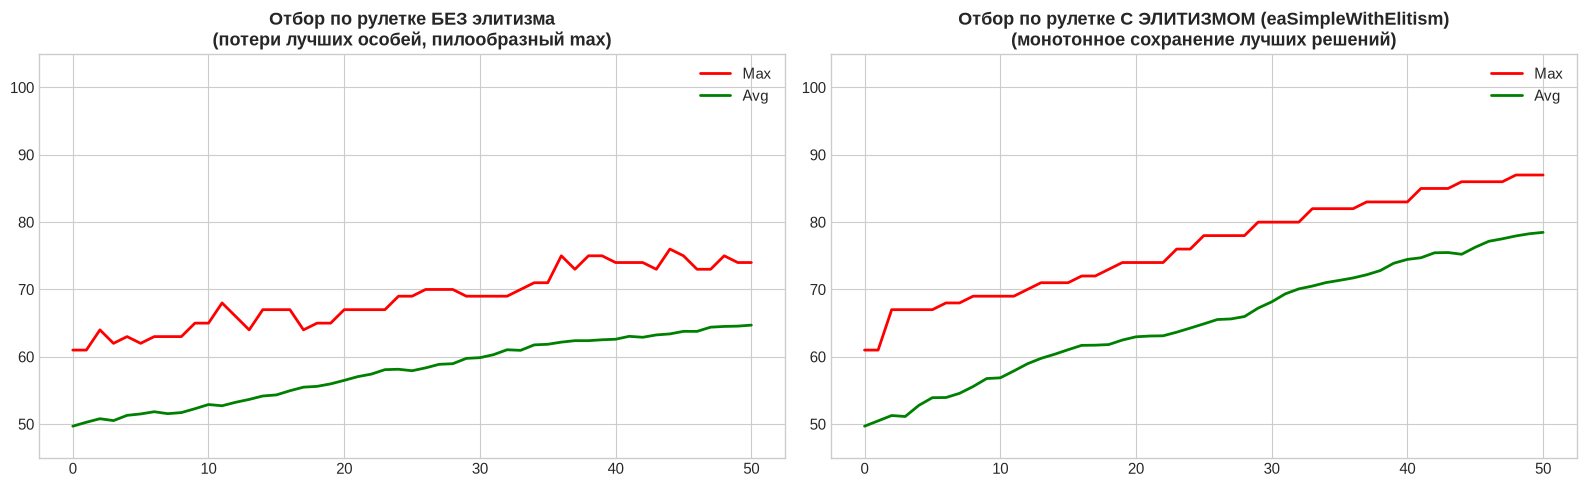

In [11]:
# Отбор по правилу рулетки без элитизма
tb_roulette = setup_toolbox(sel_operator=tools.selRoulette)

random.seed(42)
pop_roulette = tb_roulette.populationCreator(n=200)
_, log_roulette = algorithms.eaSimple(pop_roulette, tb_roulette, cxpb=0.9, mutpb=0.1, ngen=50, stats=stats, verbose=False)
max_r, avg_r = log_roulette.select("max", "avg")

# Отбор по правилу рулетки С ЭЛИТИЗМОМ
hof_r = tools.HallOfFame(5)
random.seed(42)
pop_roulette_elit = tb_roulette.populationCreator(n=200)
_, log_roulette_elit = eaSimpleWithElitism(
    pop_roulette_elit,
    tb_roulette,
    cxpb=0.9,
    mutpb=0.1,
    ngen=50,
    stats=stats,
    halloffame=hof_r,
    verbose=False
)
max_re, avg_re = log_roulette_elit.select("max", "avg")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(max_r, color='red', linewidth=2, label='Max')
axes[0].plot(avg_r, color='green', linewidth=2, label='Avg')
axes[0].set_title('Отбор по рулетке БЕЗ элитизма\n(потери лучших особей, пилообразный max)', fontweight='bold')
axes[0].set_ylim(45, 105)
axes[0].grid(True)
axes[0].legend()

axes[1].plot(max_re, color='red', linewidth=2, label='Max')
axes[1].plot(avg_re, color='green', linewidth=2, label='Avg')
axes[1].set_title('Отбор по рулетке С ЭЛИТИЗМОМ (eaSimpleWithElitism)\n(монотонное сохранение лучших решений)', fontweight='bold')
axes[1].set_ylim(45, 105)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

**Выводы по Эксперименту 5 и 6:**
- При использовании метода рулетки без элитизма лучшая особь может быть случайно не отобрана или повреждена при скрещивании/мутации, что приводит к сильным проседаниям максимальной приспособленности (левый график, стр. 39 методички).
- Применение разработанного алгоритма `eaSimpleWithElitism` гарантирует сохранение лучших особей в зале славы и передачу их в следующее поколение в неизменном виде, что полностью стабилизирует процесс эволюции (правый график).

---
## Итоговые выводы по лабораторной работе №2
1. **Преимущества пакета DEAP**: Использование фреймворка DEAP позволило сократить объем служебного кода в несколько раз, обеспечив гибкую модульную настройку типов данных и генетических операторов.
2. **Зал славы (Hall of Fame)**: Продемонстрирована эффективность сохранения лучших найденных хромосом независимо от стохастических потерь в популяции.
3. **Элитизм**: Разработана модификация эволюционного алгоритма `eaSimpleWithElitism`, гарантирующая строго монотонный неубывающий характер кривой максимальной приспособленности.
4. **Комплексный анализ операторов**:
   - Двухточечное скрещивание сходится быстрее одноточечного;
   - Завышенная мутация разрушает структуру хромосом, а слишком низкая приводит к стагнации;
   - Рулеточный отбор требует обязательного применения элитизма.